# Лабораторная работа 4. Акустическая модель

Юдин Артём М4221

**Цель работы:** Обучение акустической модели FastSpeech2 на подготовленных в работах №1–3 данных и оценка того, что получилось.

Сравниваются четыре запуска из `runs/baseline`: фонемы G2P, фонемы GT, длительности MFA и предикторы высоты и энергии. Кривые loss читаются из `epoch_history.csv`. MCD и отношение числа кадров — из `eval/mcd.csv` на одних и тех же 120 отложенных предложениях.

Порог приёмки: MCD модели ниже MCD постоянного мела.


# 1. Запуски

Ноутбук запускается из `labs/lab4_acoustic`. У каждого запуска в `runs/baseline/baseline_<имя>/` лежат история эпох и `eval/mcd.csv`.

- `mcd_model` - расстояние между мел-кепстром предсказанного mel после Griffin–Lim и исходной записью.
- `mcd_constant` - то же расстояние для постоянного mel: модель должна быть ниже этой величины.
- `frames_model / frames_natural` показывает длительность: 1 означает столько же кадров, сколько у записи.


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


RUNS_DIR = Path("runs/baseline")
EXPERIMENTS = (
    ("baseline_g2p", "G2P"),
    ("baseline_gt", "GT"),
    ("baseline_mfa", "MFA"),
    ("baseline_pitch", "pitch/energy"),
)

HISTORIES = {}
STATES = {}
MCD = {}
for name, _label in EXPERIMENTS:
    run = RUNS_DIR / name
    history = pd.read_csv(run / "epoch_history.csv")
    for column in ("epoch", "global_step", "train_loss", "eval_loss", "unix_time"):
        history[column] = pd.to_numeric(history[column])
    HISTORIES[name] = history.sort_values("epoch")
    STATES[name] = json.loads((run / "epoch_state.json").read_text(encoding="utf-8"))
    frame = pd.read_csv(run / "eval" / "mcd.csv", sep="|", dtype={"id": str})
    for column in ("mcd_model", "mcd_constant", "frames_natural", "frames_model"):
        frame[column] = pd.to_numeric(frame[column])
    frame["duration_ratio"] = frame["frames_model"] / frame["frames_natural"]
    MCD[name] = frame

ids = [set(frame["id"]) for frame in MCD.values()]
if any(group != ids[0] for group in ids):
    raise RuntimeError("В eval/mcd.csv разные наборы предложений")
print(f"Общих предложений: {len(ids[0])}")


Общих предложений: 120


In [2]:
rows = []
for name, label in EXPERIMENTS:
    history = HISTORIES[name]
    state = STATES[name]
    frame = MCD[name]
    span_hours = (history["unix_time"].iloc[-1] - history["unix_time"].iloc[0]) / 3600
    rows.append({
        "Модель": label,
        "Эпох": int(state["completed_epochs"]),
        "Цель": int(state["target_epochs"]),
        "Train loss": history["train_loss"].iloc[-1],
        "Eval loss": history["eval_loss"].iloc[-1],
        "Лучшая эпоха": int(history.loc[history["eval_loss"].idxmin(), "epoch"]),
        "Часы": span_hours,
        "MCD, дБ": frame["mcd_model"].mean(),
        "MCD constant, дБ": frame["mcd_constant"].mean(),
        "Отношение кадров": frame["duration_ratio"].mean(),
    })
SUMMARY = pd.DataFrame(rows)
SUMMARY.round(3)


Модель,Эпох,Цель,Train loss,Eval loss,Лучшая эпоха,Часы,"MCD, дБ","MCD constant, дБ",Отношение кадров
G2P,70,100,2.312,2.754,68,11.756,27.164,62.485,0.965
GT,59,100,2.485,2.810,58,9.897,27.598,62.485,0.950
MFA,100,100,2.065,2.524,100,16.635,25.346,62.485,0.974
pitch/energy,100,100,2.045,2.562,100,16.842,25.549,62.485,0.970


# 2. Кривые loss

Первая эпоха у всех запусков даёт eval loss около 42, дальше кривая падает к 2–3. Нижние графики начинаются с 10-й эпохи, чтобы было видно расхождение хвостов.

Отдельной кривой `loss_dur` в этих папках нет: в `runs/baseline` сохранены история эпох и `eval/mcd.csv`. Длительность на отложенных предложениях показана отношением кадров в следующем разделе.


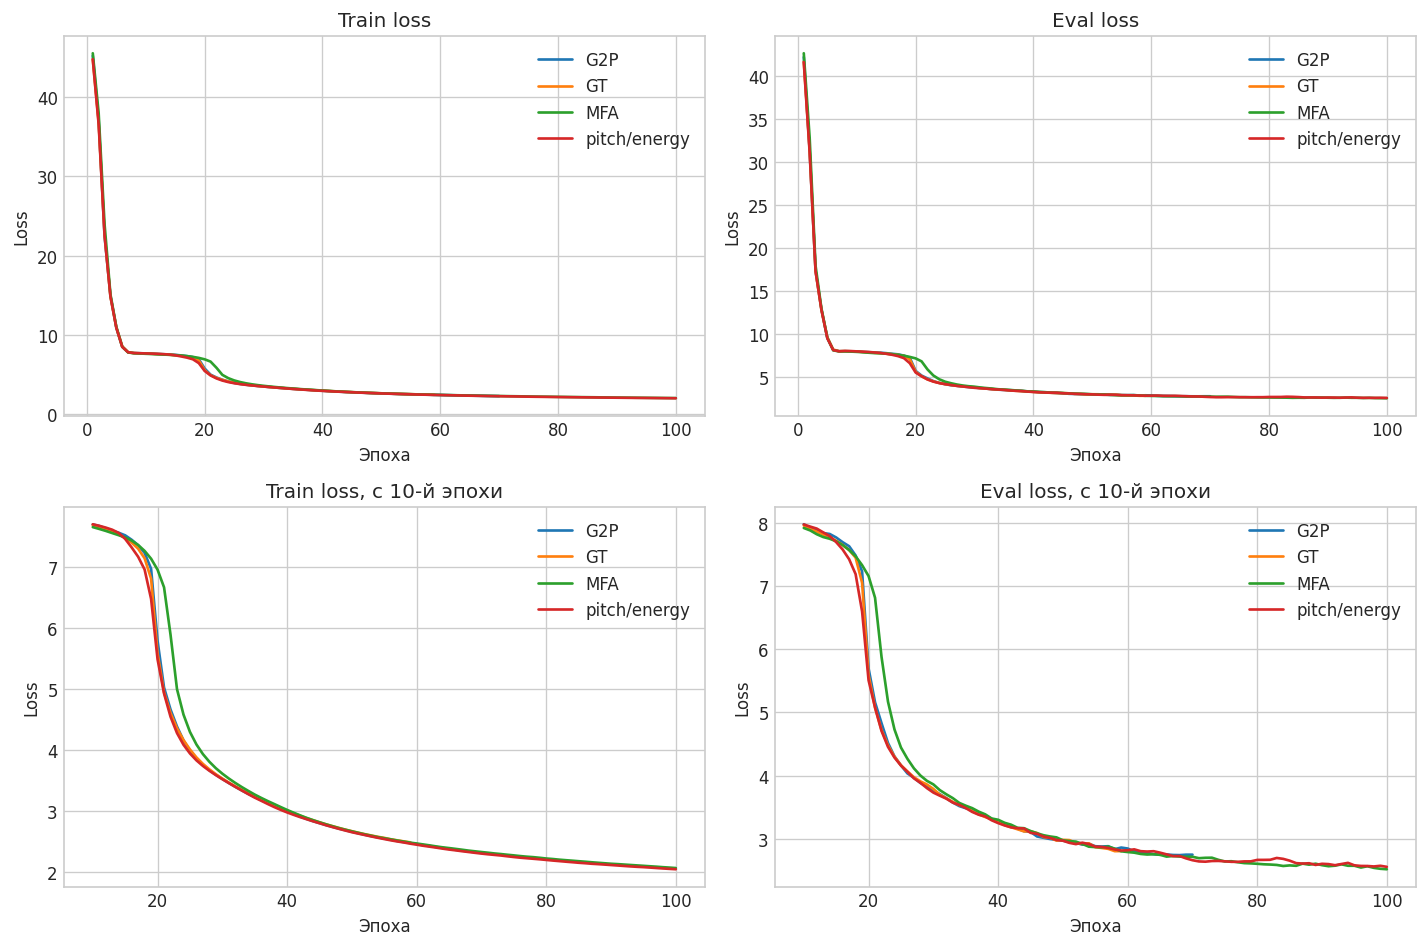

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
panels = (
    (axes[0, 0], "train_loss", None, "Train loss"),
    (axes[0, 1], "eval_loss", None, "Eval loss"),
    (axes[1, 0], "train_loss", 10, "Train loss, с 10-й эпохи"),
    (axes[1, 1], "eval_loss", 10, "Eval loss, с 10-й эпохи"),
)
for ax, column, start, title in panels:
    for name, label in EXPERIMENTS:
        history = HISTORIES[name]
        if start is not None:
            history = history.loc[history["epoch"] >= start]
        ax.plot(history["epoch"], history[column], label=label, linewidth=1.6)
    ax.set_title(title)
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Loss")
    ax.legend()
plt.tight_layout()
plt.show()


# 3. MCD и длительности

MCD измеряет спектральное расхождение после DTW. Меньшее значение ближе к записи, но само по себе не доказывает разборчивость. Отношение кадров близкое к 1 значит, что предсказанная длительность совпала с записью.


In [4]:
metric_rows = []
for name, label in EXPERIMENTS:
    frame = MCD[name]
    metric_rows.append({
        "Модель": label,
        "Предложений": len(frame),
        "MCD, дБ": frame["mcd_model"].mean(),
        "MCD median, дБ": frame["mcd_model"].median(),
        "MCD constant, дБ": frame["mcd_constant"].mean(),
        "Отношение кадров": frame["duration_ratio"].mean(),
        "Медиана отношения": frame["duration_ratio"].median(),
        "MCD ниже constant": bool((frame["mcd_model"] < frame["mcd_constant"]).all()),
    })
METRICS = pd.DataFrame(metric_rows)
METRICS.round(3)


Модель,Предложений,"MCD, дБ","MCD median, дБ","MCD constant, дБ",Отношение кадров,Медиана отношения,MCD ниже constant
G2P,120,27.164,26.698,62.485,0.965,0.969,True
GT,120,27.598,27.092,62.485,0.950,0.950,True
MFA,120,25.346,24.855,62.485,0.974,0.971,True
pitch/energy,120,25.549,25.079,62.485,0.970,0.975,True


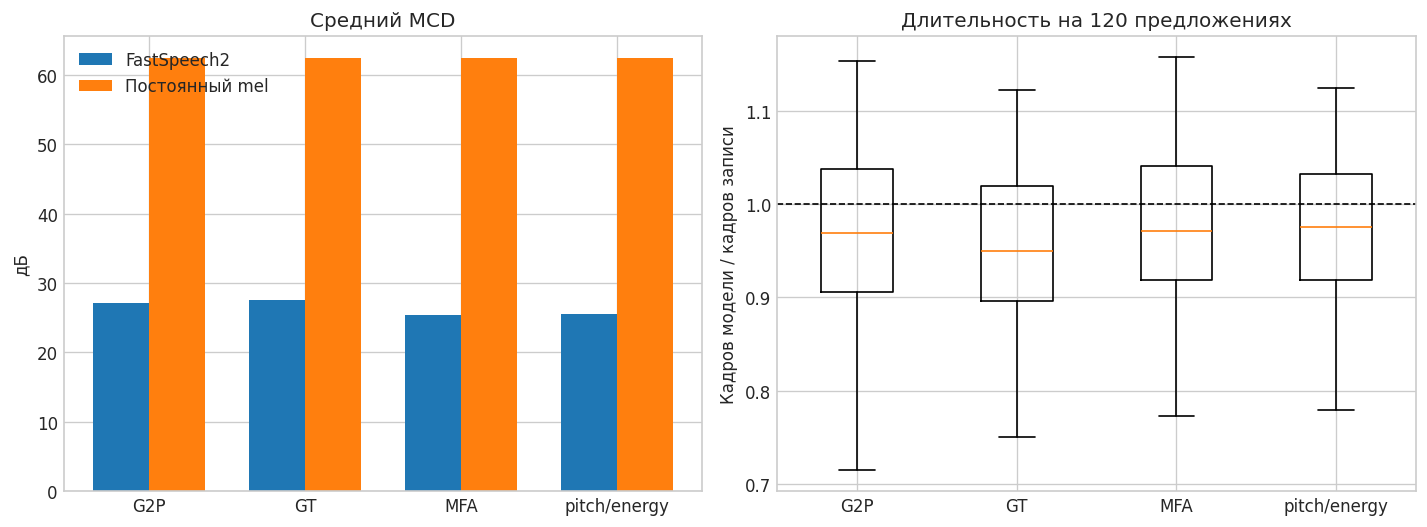

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(METRICS))
axes[0].bar(x - 0.18, METRICS["MCD, дБ"], 0.36, label="FastSpeech2")
axes[0].bar(x + 0.18, METRICS["MCD constant, дБ"], 0.36, label="Постоянный mel")
axes[0].set_xticks(x, METRICS["Модель"])
axes[0].set_ylabel("дБ")
axes[0].set_title("Средний MCD")
axes[0].legend()

ratio_groups = [MCD[name]["duration_ratio"].to_numpy() for name, _label in EXPERIMENTS]
axes[1].boxplot(
    ratio_groups,
    tick_labels=[label for _name, label in EXPERIMENTS],
    showfliers=False,
)
axes[1].axhline(1.0, color="black", linestyle="--", linewidth=1)
axes[1].set_ylabel("Кадров модели / кадров записи")
axes[1].set_title("Длительность на 120 предложениях")
plt.tight_layout()
plt.show()


In [6]:
g2p = MCD["baseline_g2p"].set_index("id")["mcd_model"]
gt = MCD["baseline_gt"].set_index("id")["mcd_model"]
print(f"G2P ниже GT: {int((g2p < gt).sum())} из {len(g2p)}")
for name, label in EXPERIMENTS:
    if name == "baseline_g2p":
        continue
    other = MCD[name].set_index("id")["mcd_model"]
    print(f"{label} ниже G2P: {int((other < g2p).sum())} из {len(g2p)}")


G2P ниже GT: 83 из 120
GT ниже G2P: 37 из 120
MFA ниже G2P: 109 из 120
pitch/energy ниже G2P: 103 из 120


# 4. Итог

G2P и GT обучались одинаковым базовым FastSpeech2 и разошлись только фонемами. На 120 общих предложениях средний MCD G2P равен 27,2 дБ, GT - 27,6 дБ. G2P ближе к записи в 83 предложениях из 120. Отношение кадров 0,97 у G2P и 0,95 у GT: синтез немного короче записи.

MFA и pitch/energy дошли до 100 эпох. Их средний MCD 25,3 дБ и 25,5 дБ, отношение кадров около 0,97. MFA ниже G2P по MCD в 109 предложениях из 120. Явные длительности MFA дают самый низкий MCD из четырёх запусков. Предикторы высоты и энергии почти не отличаются от MFA по средней ошибке.

У всех четырёх запусков MCD ниже постоянного mel (около 62,5 дБ) на каждом из 120 предложений. 

Нижний диапозон mel у всех моделей почти совпал с натуральным, но верхний немного не дошёл (у моделей он был отрицательный близкий к нулю), что в целом закрывает требование близости к человеческому голосу.

По длине модели зачастую очень близки к реальной записе (среднее >= 0.95).

Все модели в целом звучат роботизировано на слух, хотя, если закрыть на это глаза, то слова отчётливые и различимы. Меня бы таким голосом не заспуфили) Но для холодных обзвоном может быть и сгодиться.

Поскольку лосс у всех моделей близкий и особо не различатеся, вариантом для исправления проблемы могло бы быть использование прокси метрик, типа Speaker Similarity и UTMOSv2, но вроде как они были оставлены на 5 работу, так что я их решил не брать.
